# Model Reliability Under Data Shift
### A reproducible statistical modelling portfolio project
**Question:** Do predictions remain reliable when evaluation moves from US-born to foreign-born respondents?

This demonstrates established validation methods on UCI Adult income data. It makes no claim of methodological novelty or suitability for consequential decisions. The outcome is reported income above $50,000 in a selected historical sample.

Read `README.md` for the full study design and measured conclusions. This notebook loads the executed experiment's outputs; `python src/run_analysis.py` rebuilds all results from raw data.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
assert (ROOT/'src/run_analysis.py').exists(), 'Start Jupyter from the project root or notebooks folder.'
sys.path.insert(0, str(ROOT/'src'))
from run_analysis import load_data, split_data, FEATURES
reports = ROOT/'reports'
df, audit = load_data()
splits = split_data(df)
audit

{'raw_rows': 48842,
 'unknown_birthplace_removed': 857,
 'exact_duplicates_removed': 51,
 'conflicting_label_rows_retained': 3893,
 'retained_rows': 47934,
 'unique_predictor_groups': 40524}

## 1. Population definition and EDA
US-born means `native-country == United-States`. Foreign-born pools all other recorded countries. Unknown birthplace is excluded, not classified as foreign-born. Country of birth is not citizenship or country of residence.

We preserve conflicting labels among identical predictor profiles. Entire profiles stay in one partition within each population; only exact full-row duplicates are removed. This avoids discarding ambiguous outcomes and limits overlap leakage.

The displayed “Foreign-born” label is shorthand for other recorded birthplaces and includes US territories; it is not a precise Census nativity classification.

,split,n,prevalence,age_mean,education_mean,hours_mean,female_share
0,train,26234,0.2423,38.6928,10.1602,40.3919,0.3367
1,source_cal,8711,0.2464,38.7615,10.1949,40.7232,0.3275
2,source_test,8847,0.2471,38.6870,10.1674,40.3301,0.3289
3,target_cal,2074,0.1861,37.6813,9.0251,39.9002,0.3129
4,target_test,2068,0.1871,38.4613,8.9826,40.2906,0.3303


,population,age,education-num,capital-gain,capital-loss,hours-per-week,workclass,marital-status,occupation,relationship,race,sex
0,Foreign-born,0.0,0.0,0.0,0.0,0.0,0.053839,0.0,0.053839,0.0,0.0,0.0
1,US-born,0.0,0.0,0.0,0.0,0.0,0.057682,0.0,0.057910,0.0,0.0,0.0


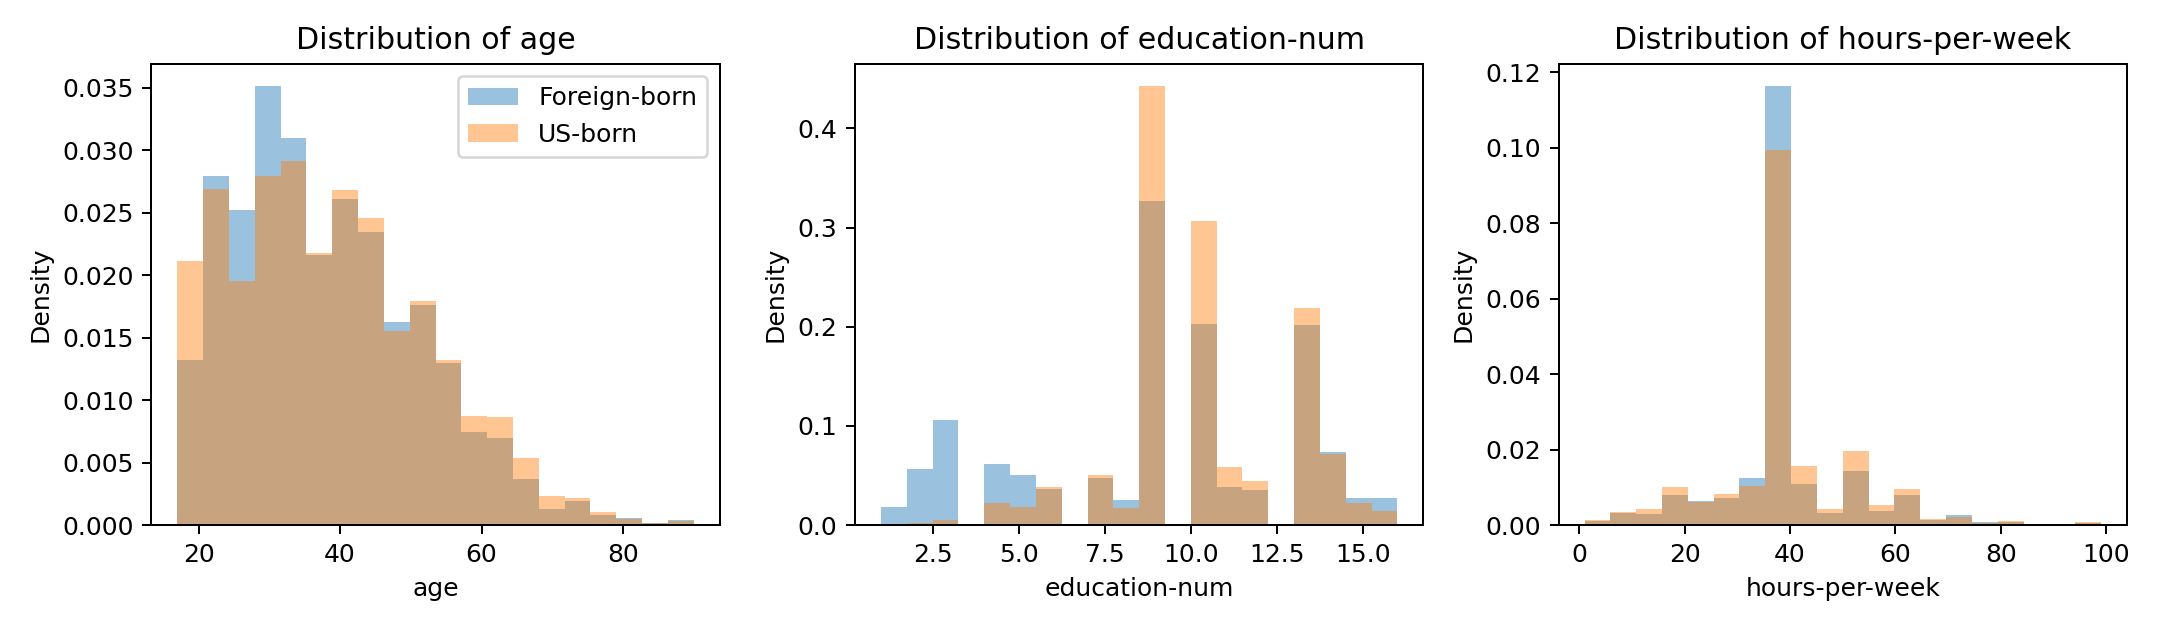

In [2]:
display(pd.read_csv(reports/'population_summary.csv').round(4))
display(pd.read_csv(reports/'missingness.csv'))
display(Image(filename=str(reports/'figures/population_shift.png')))

In [3]:
display(df.groupby(['population','sex']).y.agg(['size','mean']))
display(pd.crosstab(df.population, df.workclass, normalize='index').round(3))
display(df[df.population=='Foreign-born']['native-country'].value_counts().head(10))

size      mean
population   sex                    
Foreign-born Female   1332  0.096096
             Male     2810  0.229537
US-born      Female  14596  0.110510
             Male    29196  0.310830

workclass,Federal-gov,Local-gov,Never-worked,Private,Self-emp-inc,Self-emp-not-inc,State-gov,Without-pay
population,,,,,,,,
Foreign-born,0.022,0.041,0.0,0.804,0.033,0.073,0.027,0.0
US-born,0.032,0.071,0.0,0.730,0.037,0.085,0.045,0.0


native-country
Mexico         943
Philippines    294
Germany        206
Puerto-Rico    184
Canada         182
El-Salvador    155
India          151
Cuba           138
England        127
China          122
Name: count, dtype: int64

## 2. Design, assumptions and preprocessing
Source profile groups are split approximately 60% training / 20% calibration / 20% test. Target profile groups are split 50% calibration / 50% test, with stratification by the group's majority label and a fixed seed. Row proportions can differ from group proportions.

Medians, category modes, scales and one-hot vocabulary are learned **only from source training**. Unknown categories are safely ignored. We omit `native-country` (population definition), `fnlwgt` (survey weight), and redundant categorical `education` (retain `education-num`). Sensitive attributes remain in this educational model and are discussed in limitations.

Logistic regression assumes additive linear log odds after encoding; boosted trees allow nonlinearities and interactions. Both use predeclared parameters, without selecting a model based on target test results. HistGradientBoosting is the comparison model; XGBoost is not required.

In [4]:
display(pd.read_csv(reports/'split_manifest.csv').groupby('split').agg(rows=('y','size'),groups=('group_id','nunique'),prevalence=('y','mean')))

,rows,groups,prevalence
split,,,
source_cal,8711,7293,0.246355
source_test,8847,7294,0.247089
target_cal,2074,2028,0.186114
target_test,2068,2029,0.187137
train,26234,21880,0.242281


## 3. Discrimination, probability accuracy and uncertainty
ROC-AUC measures ranking across classes. PR-AUC here is **average precision (AP)**, not trapezoidal PR area; prevalence must accompany it. Brier score is the mean squared probability error (lower is better), combining calibration and discrimination. A constant prevalence prediction has Brier score $\pi(1-\pi)$.

Intervals use 500 percentile cluster-bootstrap resamples of test predictor groups. They condition on the fitted model, fitted recalibrator and chosen split; they do not cover training, calibration-fitting or split uncertainty. Source–target differences resample the two domains independently. Recalibration Brier changes use paired predictions on the same target rows.

In [5]:
metrics = pd.read_csv(reports/'metrics.csv')
display(metrics.round(4))
display(pd.read_csv(reports/'shift_deltas.csv').round(4))
display(pd.read_csv(reports/'paired_brier_deltas.csv').round(5))

,model,domain,variant,n,prevalence,roc_auc,pr_auc_ap,brier,mean_probability,roc_auc_lo,roc_auc_hi,pr_auc_ap_lo,pr_auc_ap_hi,brier_lo,brier_hi
0,Logistic regression,source_test,Original,8847,0.2471,0.9064,0.7694,0.1039,0.2411,0.8994,0.9134,0.7516,0.7842,0.0991,0.1085
1,Logistic regression,source_test,Source recalibrated,8847,0.2471,0.9064,0.7694,0.1040,0.2387,0.8994,0.9134,0.7516,0.7842,0.0992,0.1086
2,Logistic regression,source_test,Target recalibrated,8847,0.2471,0.9064,0.7694,0.1094,0.2042,0.8994,0.9134,0.7516,0.7842,0.1044,0.1145
3,Logistic regression,target_test,Original,2068,0.1871,0.9077,0.7069,0.0917,0.2173,0.8910,0.9230,0.6628,0.7527,0.0835,0.0992
4,Logistic regression,target_test,Source recalibrated,2068,0.1871,0.9077,0.7069,0.0912,0.2154,0.8910,0.9230,0.6628,0.7527,0.0832,0.0987
5,Logistic regression,target_test,Target recalibrated,2068,0.1871,0.9077,0.7069,0.0899,0.1860,0.8910,0.9230,0.6628,0.7527,0.0819,0.0975
6,Gradient boosting,source_test,Original,8847,0.2471,0.9297,0.8338,0.0892,0.2444,0.9233,0.9360,0.8199,0.8489,0.0848,0.0942
7,Gradient boosting,source_test,Source recalibrated,8847,0.2471,0.9297,0.8338,0.0891,0.2433,0.9233,0.9360,0.8199,0.8489,0.0847,0.0942
8,Gradient boosting,source_test,Target recalibrated,8847,0.2471,0.9297,0.8338,0.0922,0.2128,0.9233,0.9360,0.8199,0.8489,0.0876,0.0974
9,Gradient boosting,target_test,Original,2068,0.1871,0.9279,0.7848,0.0798,0.2156,0.9138,0.9411,0.7466,0.8203,0.0723,0.0874


,model,metric,target_minus_source,lo,hi
0,Logistic regression,roc_auc,0.0014,-0.0151,0.0159
1,Logistic regression,pr_auc_ap,-0.0624,-0.1112,-0.0155
2,Logistic regression,brier,-0.0122,-0.0211,-0.0024
3,Gradient boosting,roc_auc,-0.0018,-0.0178,0.0136
4,Gradient boosting,pr_auc_ap,-0.0490,-0.0904,-0.0110
5,Gradient boosting,brier,-0.0094,-0.0186,-0.0006


,model,domain,target_recalibration_brier_delta,lo,hi
0,Logistic regression,source_test,0.00558,0.00437,0.00680
1,Logistic regression,target_test,-0.00183,-0.00425,0.00078
2,Gradient boosting,source_test,0.00301,0.00216,0.00385
3,Gradient boosting,target_test,-0.00175,-0.00349,0.00014


## 4. Recalibration
Fit $\operatorname{logit}(p_{new}) = a + b\operatorname{logit}(p_{original})$ using either source calibration labels or target calibration labels. The latter assumes access to labeled target observations, an adaptation scenario. Final test labels are never used to train the recalibrator.

Probability clipping to $[10^{-6},1-10^{-6}]$ makes log odds finite. Positive slopes preserve ranking except for numerical clipping ties. Calibration can improve probability accuracy without materially changing AUC. Negative Brier deltas mean improvement.

Separate diagnostic intercepts and slopes fitted on **test** outcomes summarize calibration only; they do not modify predictions. Ideal values are 0 and 1.

,model,calibration_sample,intercept,slope
0,Logistic regression,source_cal,-0.0419,0.9706
1,Logistic regression,target_cal,-0.4655,0.8079
2,Gradient boosting,source_cal,0.0182,1.0476
3,Gradient boosting,target_cal,-0.3769,0.9434


,model,domain,intercept,slope
0,Logistic regression,source_test,0.0824,1.0381
1,Logistic regression,target_test,-0.4222,0.8624
2,Gradient boosting,source_test,0.0950,1.1044
3,Gradient boosting,target_test,-0.3660,0.9871


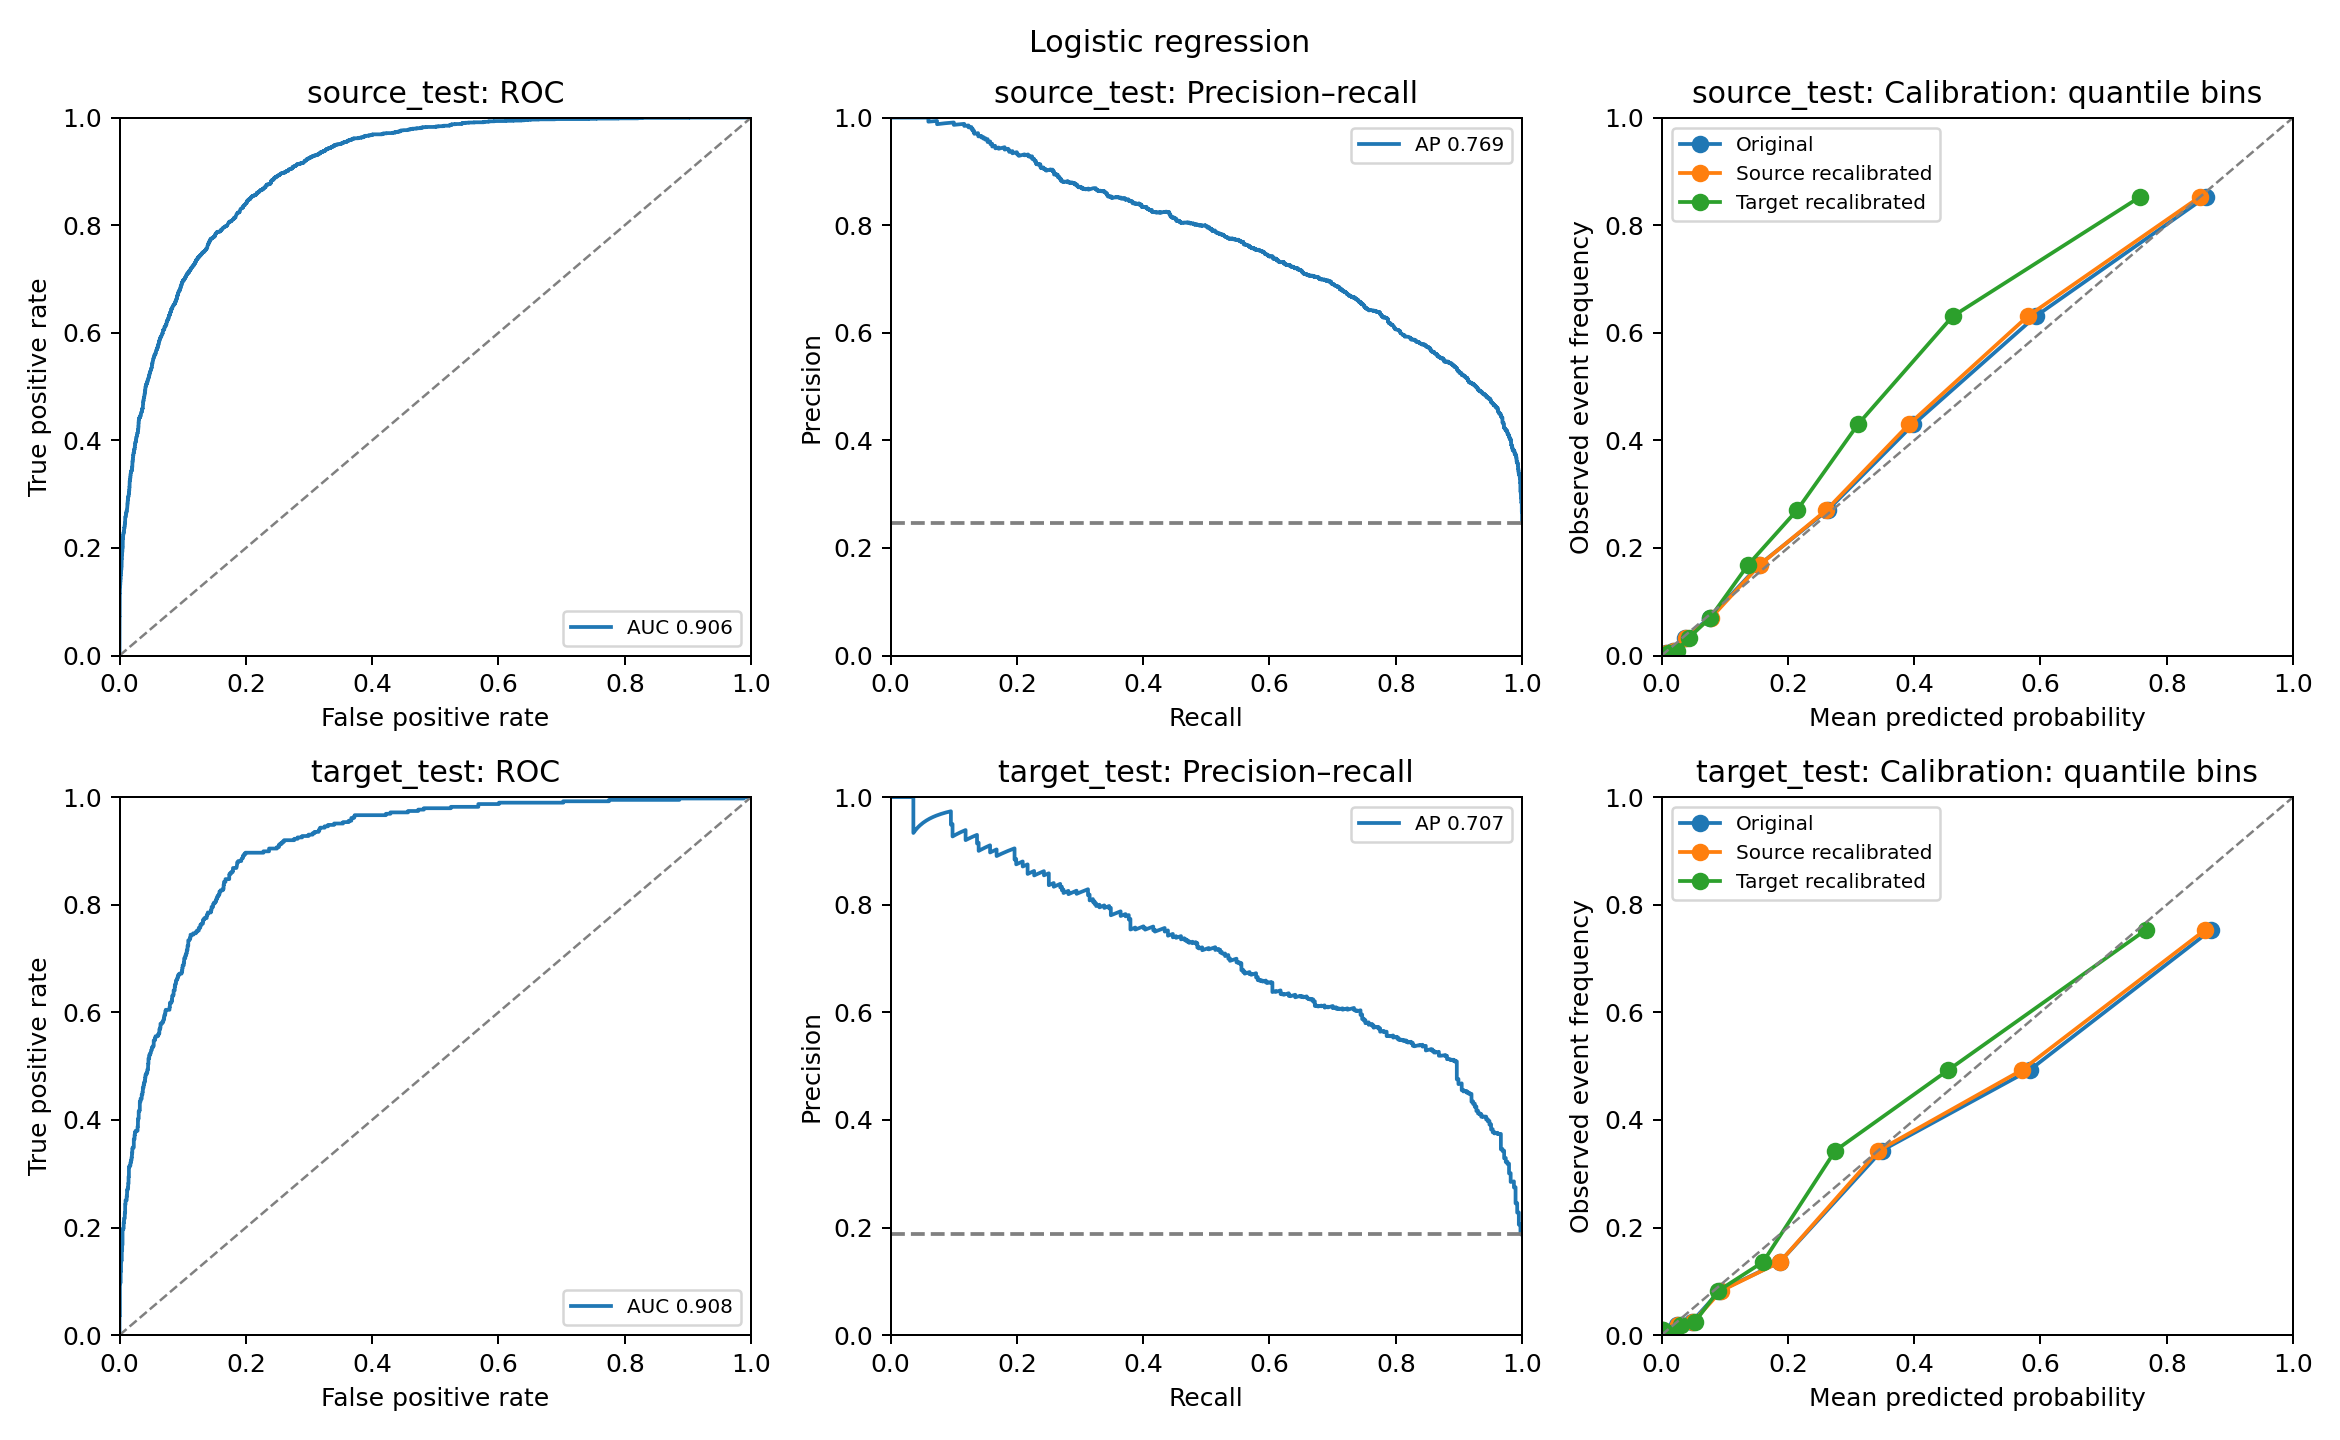

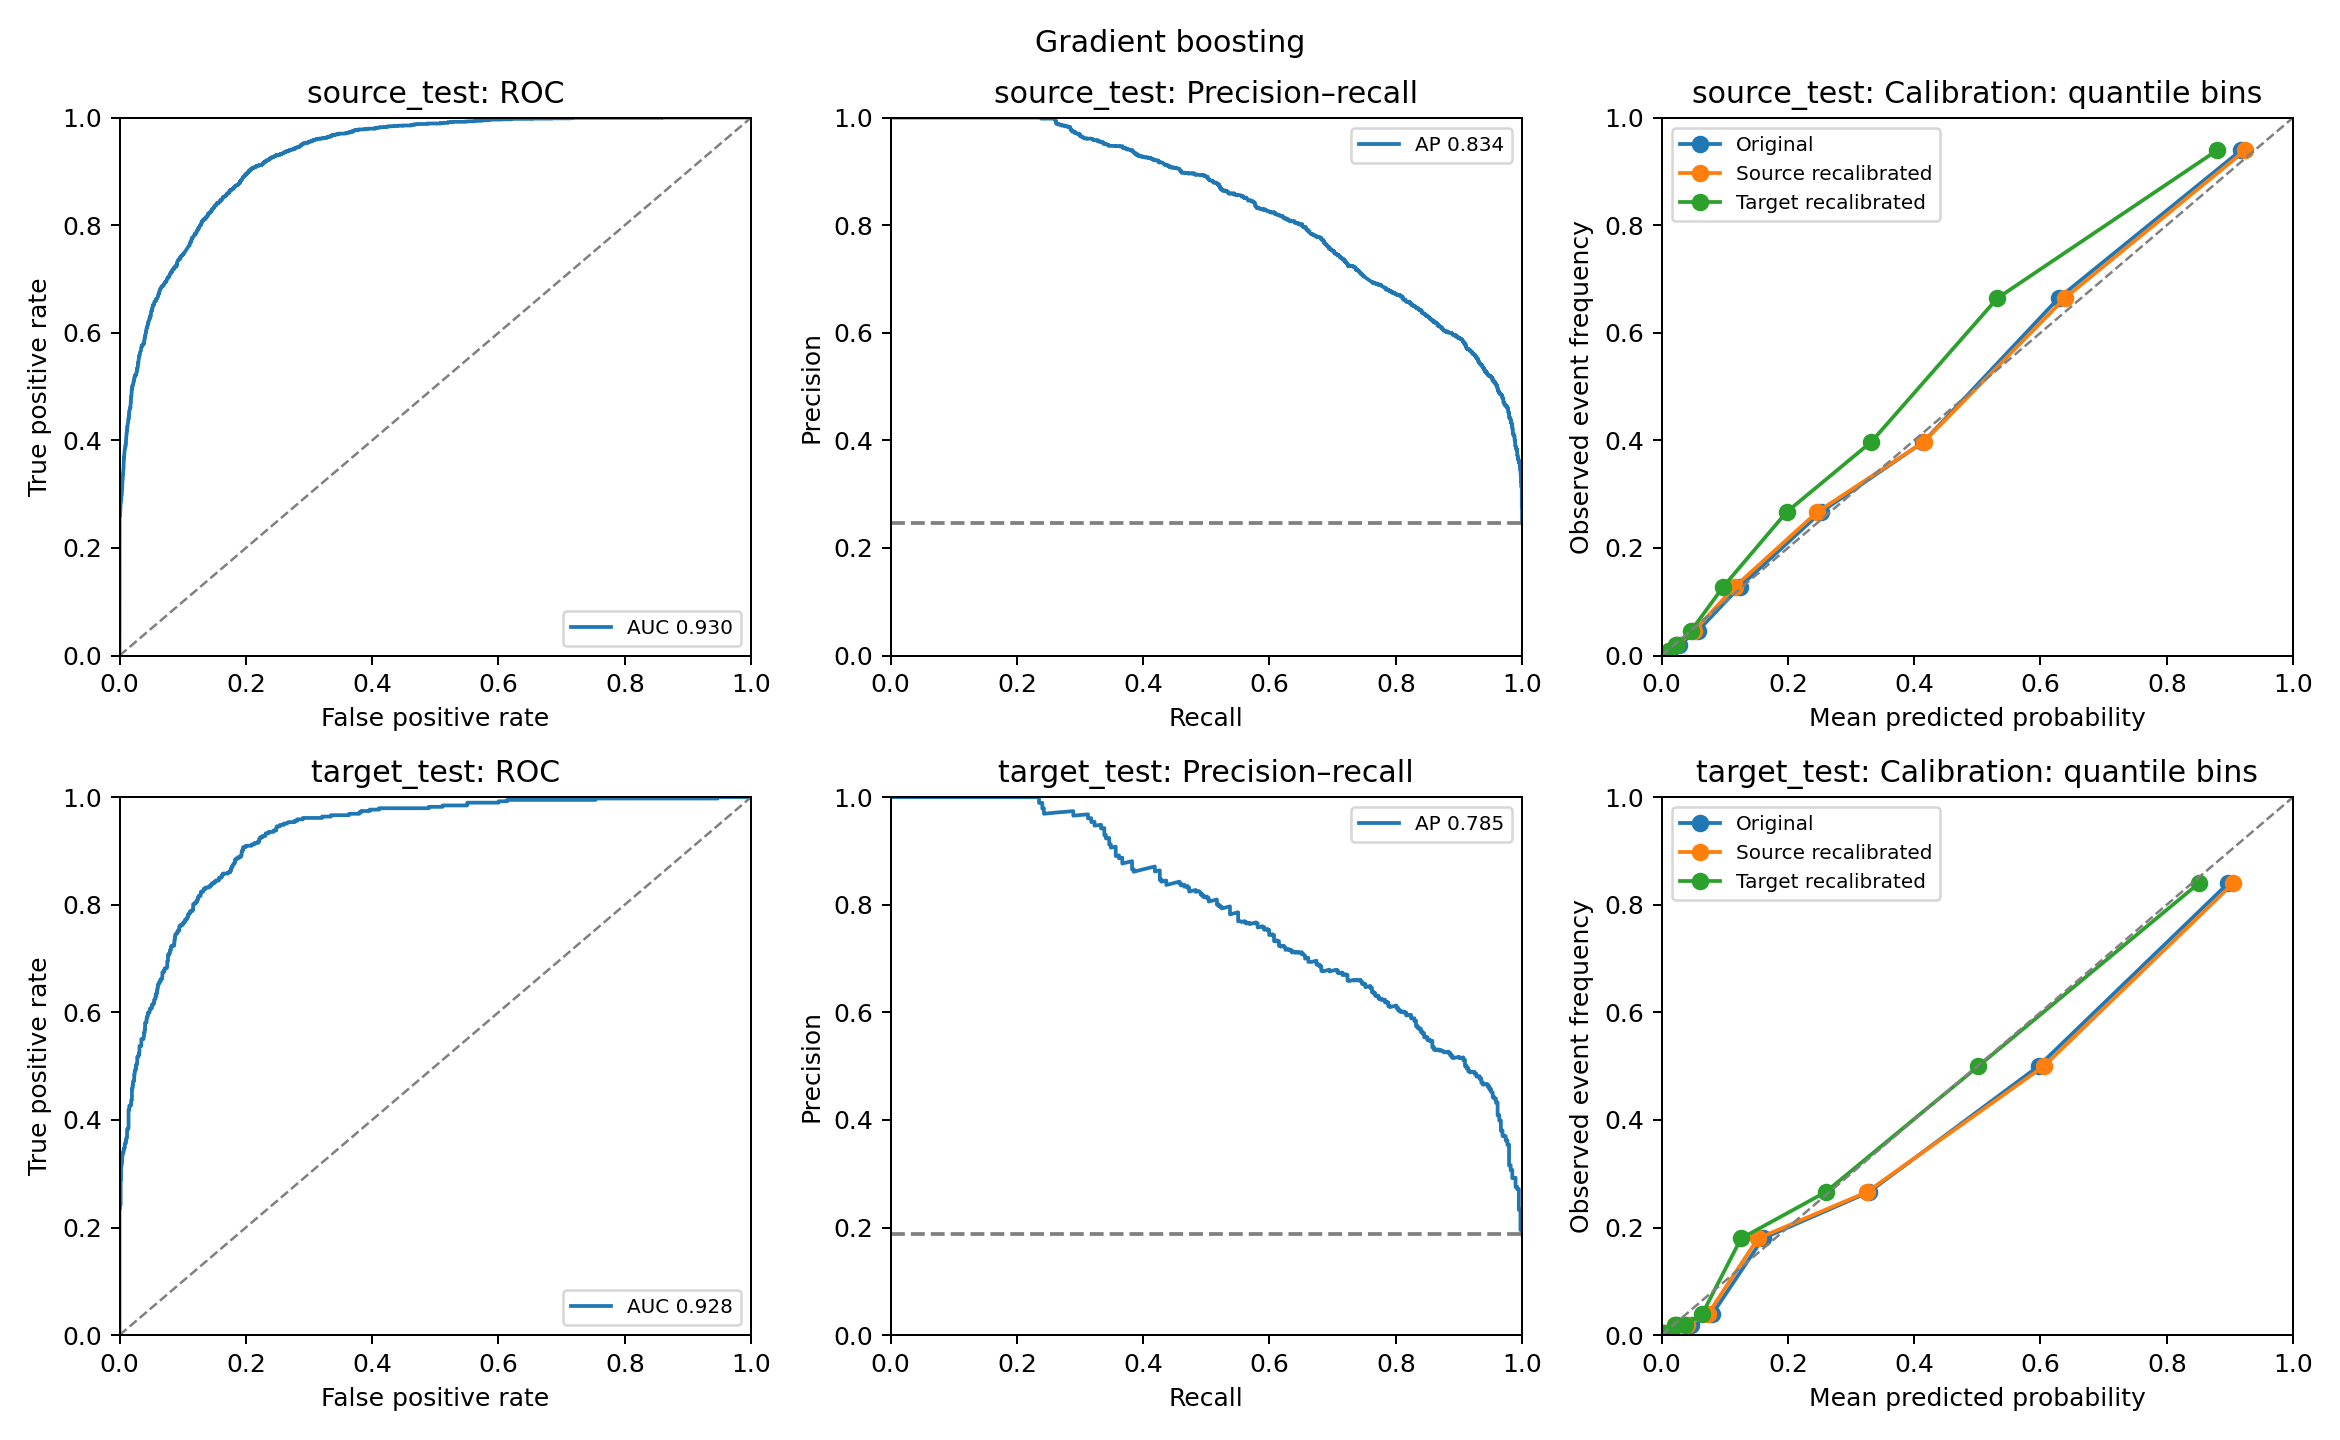

In [6]:
display(pd.read_csv(reports/'recalibration_parameters.csv').round(4))
display(pd.read_csv(reports/'calibration_diagnostics.csv').round(4))
display(Image(filename=str(reports/'figures/logistic_evaluation.png')))
display(Image(filename=str(reports/'figures/boosting_evaluation.png')))

## 5. Model interpretation and subgroup checks
Logistic coefficients are conditional associations, not causal effects. Numeric coefficients are per source-training standard deviation; categorical indicators use all levels with regularization, so they are not reference-category odds ratios. Correlated features complicate interpretation.

Sex subgroup metrics are exploratory. No multiple-comparison adjustment is applied, and they are not evidence of fairness or policy suitability.

In [7]:
coef=pd.read_csv(reports/'logistic_coefficients.csv')
display(coef.assign(magnitude=coef.log_odds_coefficient.abs()).sort_values('magnitude',ascending=False).head(15))
display(pd.read_csv(reports/'subgroup_metrics.csv').round(4))

,feature,log_odds_coefficient,magnitude
2,numeric__capital-gain,2.391740,2.391740
15,categorical__marital-status_Married-civ-spouse,1.814539,1.814539
14,categorical__marital-status_Married-AF-spouse,1.251329,1.251329
24,categorical__occupation_Farming-fishing,-1.131786,1.131786
16,categorical__marital-status_Married-spouse-absent,-1.079174,1.079174
17,categorical__marital-status_Never-married,-1.049387,1.049387
37,categorical__relationship_Own-child,-0.964551,0.964551
36,categorical__relationship_Other-relative,-0.909535,0.909535
45,categorical__sex_Female,-0.893027,0.893027
27,categorical__occupation_Other-service,-0.769579,0.769579


,model,domain,sex,n,prevalence,roc_auc,pr_auc_ap,brier,mean_probability
0,Logistic regression,source_test,Female,2910,0.1072,0.9333,0.7123,0.0525,0.1033
1,Logistic regression,source_test,Male,5937,0.3156,0.8802,0.7769,0.1290,0.3087
2,Logistic regression,target_test,Female,683,0.0864,0.9256,0.5943,0.0545,0.1110
3,Logistic regression,target_test,Male,1385,0.2368,0.8928,0.7287,0.1101,0.2697
4,Gradient boosting,source_test,Female,2910,0.1072,0.9475,0.7806,0.0453,0.1053
5,Gradient boosting,source_test,Male,5937,0.3156,0.9107,0.8407,0.1107,0.3126
6,Gradient boosting,target_test,Female,683,0.0864,0.9351,0.6574,0.0500,0.1136
7,Gradient boosting,target_test,Male,1385,0.2368,0.9184,0.8050,0.0945,0.2659


## 6. Interpretation and limitations
Use the measured source–target differences and their intervals rather than assuming every metric must deteriorate under shift. Changing prevalence and case mix complicates cross-population comparisons; calibration curves with different quantile bin boundaries are descriptive.

This dataset is old, selected and pooled across heterogeneous countries. Birthplace is observational, not an intervention. Unweighted record-level results are not survey population estimates. Bootstrap assumptions may be violated by household or survey dependence not represented in available fields. Splits are within the same historical dataset, not external or temporal validation. No conclusions about current income, immigration, health outcomes or deployment follow from this exercise.

Next steps: repeat grouped splits; bootstrap the full training/calibration pipeline; study country-specific heterogeneity when counts permit; remove sensitive features in a sensitivity analysis; compare weighting strategies with appropriate survey design metadata.

In [8]:
import json
display(json.loads((reports/'run_metadata.json').read_text()))

{'seed': 2026,
 'bootstrap_replicates': 500,
 'audit': {'raw_rows': 48842,
  'unknown_birthplace_removed': 857,
  'exact_duplicates_removed': 51,
  'conflicting_label_rows_retained': 3893,
  'retained_rows': 47934,
  'unique_predictor_groups': 40524},
 'python': '3.12.7',
 'sklearn': '1.5.1',
 'numpy': '1.26.4',
 'pandas': '2.2.2',
 'matplotlib': '3.9.2',
 'raw_sha256': {'adult.data': '5b00264637dbfec36bdeaab5676b0b309ff9eb788d63554ca0a249491c86603d',
  'adult.names': 'c248284c0b5de30c9e1958d6cdd168a34a654758b620e68f46aefa83fc0a576a',
  'adult.test': 'a2a9044bc167a35b2361efbabec64e89d69ce82d9790d2980119aac5fd7e9c05'}}